In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

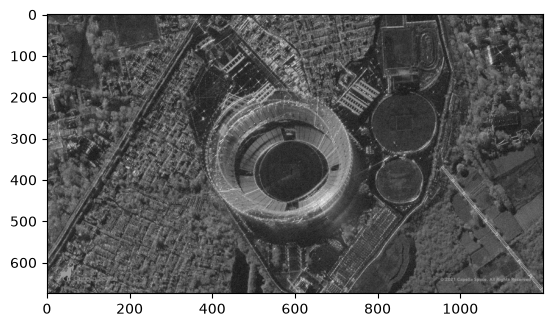

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.show()

# 1. Зашумление изображения при помощи шума Гаусса, постоянного шума.

Шум Гаусса

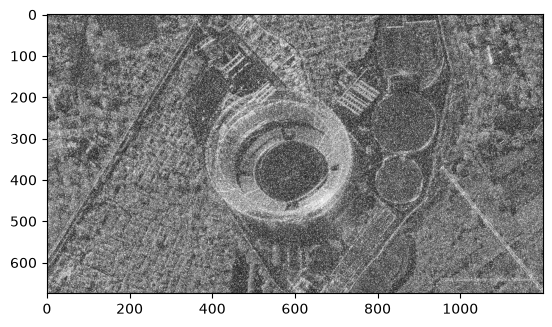

In [3]:
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)
image_noise_gauss = cv2.add(image_gray, noise_gauss)
plt.imshow(image_noise_gauss, cmap='gray')
plt.show()

Постоянный (равномерный) шум

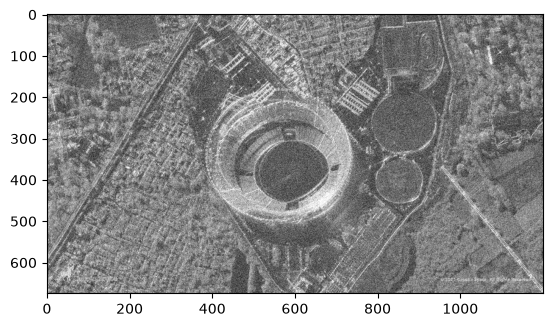

In [4]:
A, B = 0, 100
noise_uniform = np.random.uniform(A, B, image_gray.shape)
image_noise_uniform = np.clip(image_gray.astype(np.float32) + noise_uniform, 0, 255).astype(np.uint8)
plt.imshow(image_noise_uniform, cmap='gray')
plt.show()

# 2. Тестирование медианного фильтра, фильтра гаусса, билатериального фильтра, фильтра нелокальных средних с различными параметрами.

In [5]:
scores = {}

def process(label, res_g, res_u):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, noise_name, res in zip(axes, ("Гауссов шум", "Равномерный шум"), (res_g, res_u)):
        mse = mean_squared_error(image_gray, res)
        ssim = structural_similarity(image_gray, res)
        scores[(noise_name, label)] = (mse, ssim)
        ax.imshow(res, cmap='gray')
        ax.set_title(f"{label} , {noise_name}")
    plt.show()

Медианный фильтр

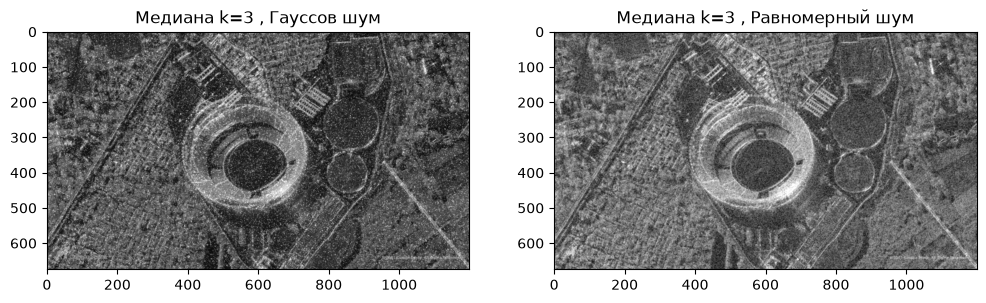

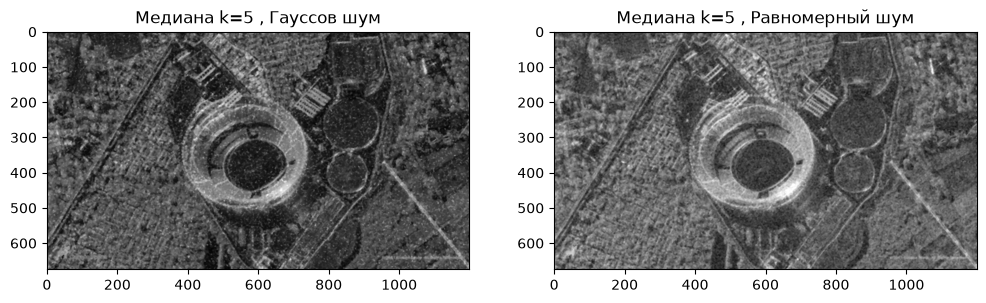

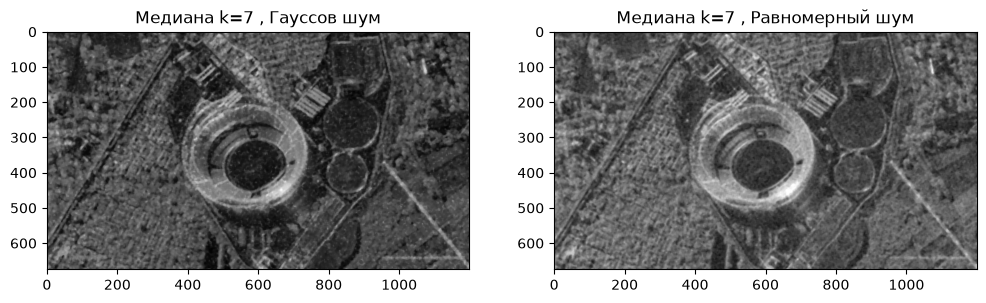

In [6]:
for k in (3, 5, 7):
    process(f"Медиана k={k}",
            cv2.medianBlur(image_noise_gauss, k),
            cv2.medianBlur(image_noise_uniform, k))

Фильтр Гаусса

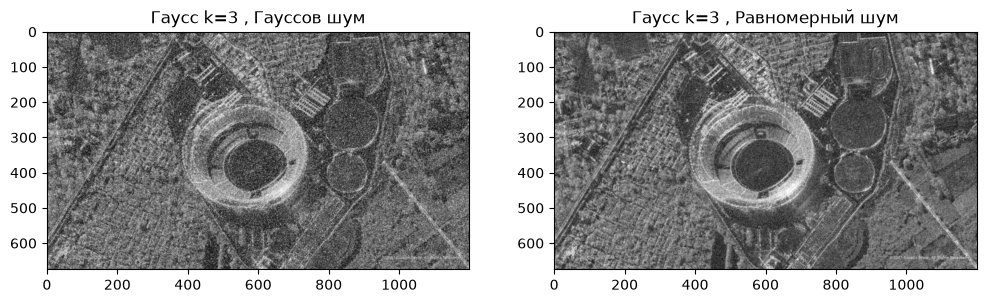

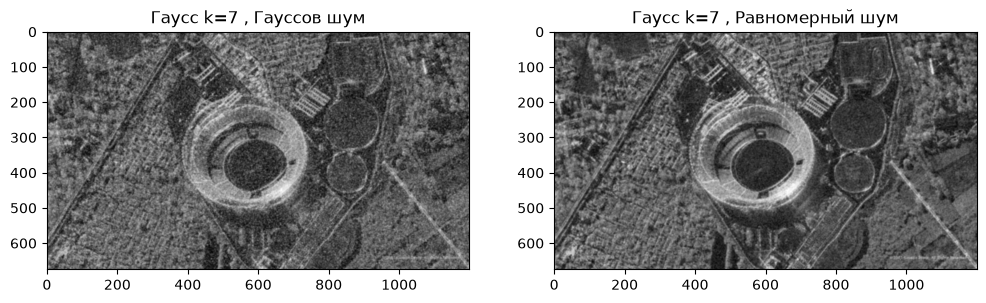

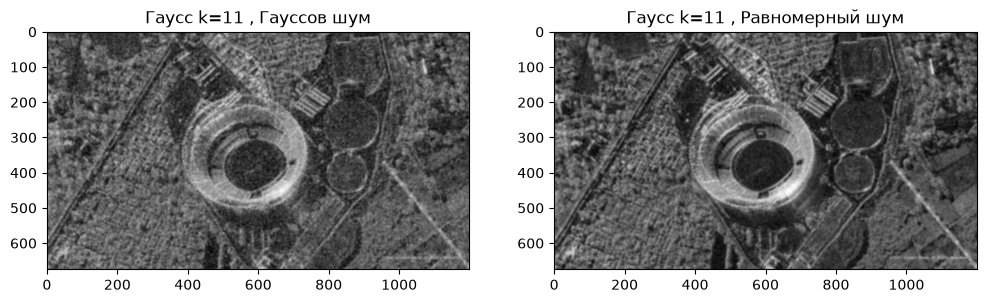

In [7]:
for k in (3, 7, 11):
    process(f"Гаусс k={k}",
            cv2.GaussianBlur(image_noise_gauss, (k, k), 0),
            cv2.GaussianBlur(image_noise_uniform, (k, k), 0))

Билатеральный фильтр

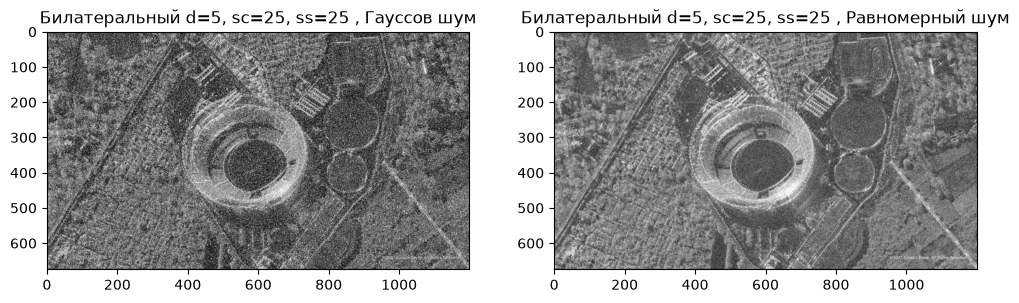

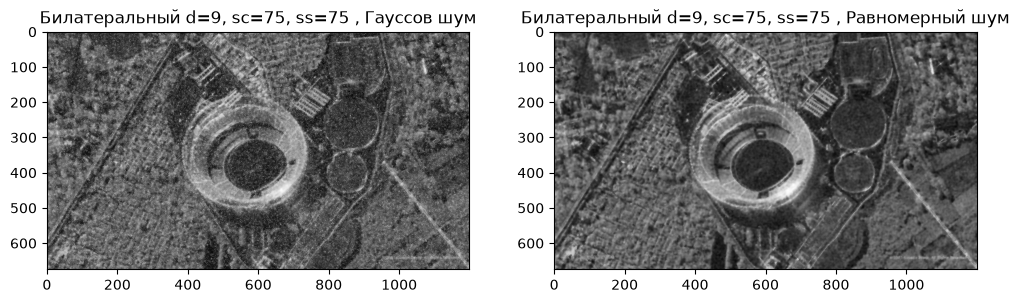

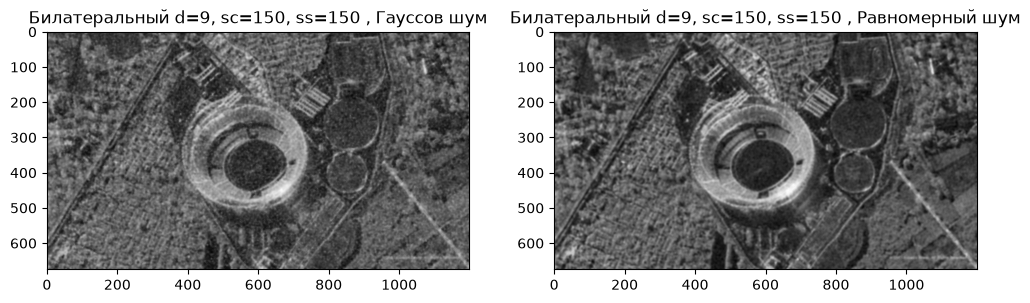

In [8]:
for d, sc, ss in ((5, 25, 25), (9, 75, 75), (9, 150, 150)):
    process(f"Билатеральный d={d}, sc={sc}, ss={ss}",
            cv2.bilateralFilter(image_noise_gauss, d, sc, ss),
            cv2.bilateralFilter(image_noise_uniform, d, sc, ss))

Фильтр нелокальных средних

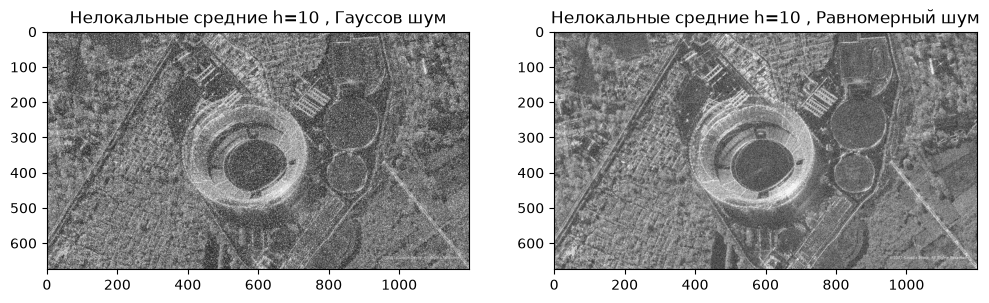

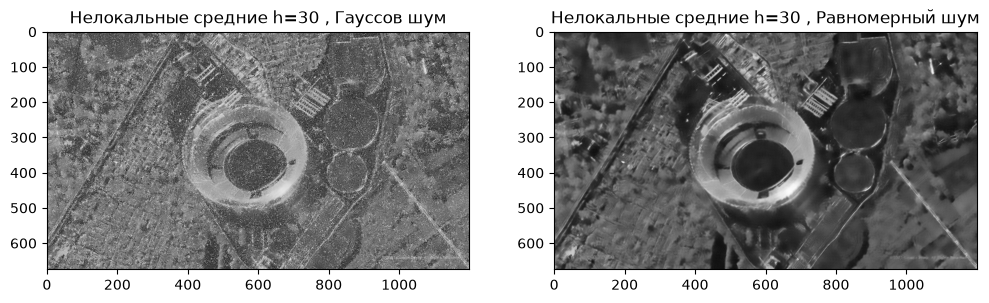

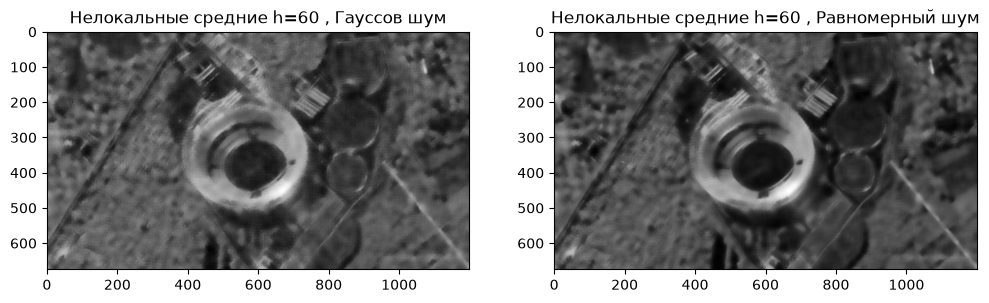

In [9]:
for h in (10, 30, 60):
    process(f"Нелокальные средние h={h}",
            cv2.fastNlMeansDenoising(image_noise_gauss, h=h),
            cv2.fastNlMeansDenoising(image_noise_uniform, h=h))

# 3. Выяснение, какой фильтр показал лучший результат фильтрации шума.

In [10]:
for noise_name in ("Гауссов шум", "Равномерный шум"):
    rows = {label: val for (n, label), val in scores.items() if n == noise_name}
    print(noise_name)
    for label, (mse, ssim) in rows.items():
        print(f"  {label:<58} MSE = {mse:>8.2f}   SSIM = {ssim:.4f}")
    best_mse = min(rows, key=lambda l: rows[l][0])
    best_ssim = max(rows, key=lambda l: rows[l][1])
    print(f"  Лучший по MSE:  {best_mse}")
    print(f"  Лучший по SSIM: {best_ssim}\n")

Гауссов шум
  Медиана k=3                                                MSE =  1038.05   SSIM = 0.4282
  Медиана k=5                                                MSE =   706.03   SSIM = 0.4702
  Медиана k=7                                                MSE =   682.57   SSIM = 0.4336
  Гаусс k=3                                                  MSE =  1903.45   SSIM = 0.4403
  Гаусс k=7                                                  MSE =  1721.20   SSIM = 0.4925
  Гаусс k=11                                                 MSE =  1728.74   SSIM = 0.4580
  Билатеральный d=5, sc=25, ss=25                            MSE =  3872.58   SSIM = 0.1847
  Билатеральный d=9, sc=75, ss=75                            MSE =  1837.55   SSIM = 0.3145
  Билатеральный d=9, sc=150, ss=150                          MSE =  1547.91   SSIM = 0.4413
  Нелокальные средние h=10                                   MSE =  4230.67   SSIM = 0.1870
  Нелокальные средние h=30                                   MSE =  

Итог: для Гауссова шума лучше всего справился медианный фильтр по MSE и фильтр Гаусса по SSIM, для равномерного шума лучше всего справился фильтр нелокальных средних по MSE и фильтр Гаусса по SSIM.